# Full-wave cloaks and the gauge freedom of anisotropic media

A small finite-element solver for E_z waves in anisotropic magnetic media is built here and used for two things: cloaks of arbitrary shape from a coordinate map that automatic differentiation turns into a medium, and a demonstration that scattering data cannot tell apart two media related by a diffeomorphism that is the identity outside a region. The second is the gauge freedom of the anisotropic inverse problem, and the cloak is its singular limit.

## What this notebook shows

- A vectorized Q1 finite-element solver with a perfectly matched layer, validated against the exact Mie, PEC-cylinder and Neumann-cylinder (hole) series, with the observed convergence order.
- The cylindrical cloak and a squircle-shaped cloak, both generated from the same few lines: a map, `jax.jacfwd`, and the transformation formula. No Jacobian is derived by hand. Each is lined with PEC and with a magnetic-wall hole; the hole lining leaves much less scattering (the full-wave counterpart of notebook 02, section 4).
- A smooth twist-and-dilation diffeomorphism, supported in a disk, whose pulled-back medium produces the same scattering data as the original object, while the naively deformed object does not.
- Why this freedom is absent for isotropic nonmagnetic media in two dimensions: conformal maps are rigid (identity theorem), so this particular gauge freedom is absent in the project's isotropic class (uniqueness itself rests on other theorems, cited in section 4).

## Conventions

Time dependence is exp(-i omega t), so outgoing cylindrical waves are Hankel functions of the first kind and loss is a positive imaginary part of eps or mu. Lengths are in free-space wavelengths at the design frequency, lambda0 = 1 and k0 = 2 pi. The polarization with E along z is called TM (E_z), as in `docs/DESIGN.md`; the book calls it TE (sections 5 and 27). Notebooks 01, 02, 04 and 05 are referred to by number; nothing is imported from them.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/cloaking (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib
_src = pathlib.Path.cwd().resolve().parents[1] / "src"   # use the bayes_scatter that ships with this checkout
if (_src / "bayes_scatter").is_dir() and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))
from bayes_scatter.mie import mie_coefficients
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import splu
from scipy.special import jv, hankel1, jvp, h1vp
from scipy.optimize import brentq

## 1. The equation and the solver

**Equation.** For E = E_z(x, y) in a medium with in-plane permeability tensor mu_t (symmetric, 2 x 2) and permittivity eps_zz, Maxwell's equations reduce to

$$\nabla\cdot(A\,\nabla E)+k_0^2\,\varepsilon_{zz}\,E=0,\qquad A=\frac{\mu_t}{\det\mu_t}.$$

For a transformation medium (book section 32, eq. (32.5), with eps = mu) acting on a virtual medium (A', eps'), with in-plane Jacobian Lambda of the map from virtual to physical space,

$$A=\frac{\Lambda A'\Lambda^{T}}{\det\Lambda},\qquad \varepsilon_{zz}=\frac{\varepsilon'}{\det\Lambda},$$

both evaluated at the physical point whose virtual image is x'. It is convenient to define a map by its inverse g: x -> x' and to take M = dg/dx, so that Lambda = M^{-1}; then A = adj(M) A' adj(M)^T / det M and eps_zz = eps' det M, which needs no matrix inverse. The Jacobian M comes from `jax.jacfwd`, vmapped over points.

**Discretization.** Square domain [-L, L]^2 with L = 4.5, a uniform grid of bilinear (Q1) elements, 2 x 2 Gauss quadrature with A and eps_zz evaluated at the Gauss points, assembly by einsum over all elements at once, and one sparse LU factorization reused for all incident plane waves. The unknown is the scattered field u, with E = u_inc + u and u_inc = exp(i k0 d.x). The weak form is

$$\int \nabla v\cdot A\nabla u-k_0^2\varepsilon_{zz}uv=-\int\nabla v\cdot(A-I)\nabla u_{inc}+k_0^2\int(\varepsilon_{zz}-1)\,u_{inc}\,v,$$

where the right-hand side uses the physical medium: it vanishes in vacuum and in the absorbing layer. PEC regions are Dirichlet nodes, u = -u_inc. The outer boundary is a perfectly matched layer one wavelength thick, written as the same transformation formula with the complex stretch s = 1 + i sigma(x)/k0, so A = diag(s_y/s_x, s_x/s_y) and eps_zz = s_x s_y. The profile sigma is quadratic and sigma_max is set for a round-trip reflection of 1e-8 at normal incidence; u = 0 on the outer edge.

**Observable.** Sampling u on a circle of radius R_obs by bilinear interpolation and taking the angular FFT gives the partial-wave coefficients s_m of

$$u(R,\theta)=\sum_m i^m s_m H_m^{(1)}(k_0R)\,e^{im\theta}\quad(\text{incidence along }+x),\qquad \sigma_{sca}=\frac{4}{k_0}\sum_m|s_m|^2 .$$

These are the same s_m and sigma_sca as in notebook 02.

In [3]:
K0 = 2 * np.pi
HALF, XPML, DPML = 4.5, 3.5, 1.0                # half width of the box; PML starts at |x| = XPML and is DPML thick
SIGMA_MAX = 1.5 * np.log(1e8) / DPML            # exp(-2 * sigma_max * d / 3) = 1e-8 for a quadratic profile, round trip

# Reference Q1 element on [0,1]^2: local nodes (0,0),(1,0),(0,1),(1,1); 2 x 2 Gauss points.
_gp = 0.5 + np.array([-1.0, 1.0]) / (2 * np.sqrt(3))
_loc = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])
_pts = np.array([(a, b) for a in _gp for b in _gp])
_f = lambda c, s: np.where(c == 1, s, 1 - s)
_df = lambda c: np.where(c == 1, 1.0, -1.0)
PHI = np.stack([_f(c[0], _pts[:, 0]) * _f(c[1], _pts[:, 1]) for c in _loc], 1)                 # (point, node)
DPHI = np.stack([np.stack([_df(c[0]) * _f(c[1], _pts[:, 1]),
                           _f(c[0], _pts[:, 0]) * _df(c[1])], -1) for c in _loc], 1)         # (point, node, 2)


class Grid:
    """Uniform Q1 grid on [-HALF, HALF]^2 with spacing h; node (ix, iy) has number ix * n1 + iy."""
    def __init__(self, h):
        self.N = int(round(2 * HALF / h)); self.h = 2 * HALF / self.N; self.n1 = self.N + 1
        c = -HALF + self.h * np.arange(self.n1)
        self.X, self.Y = np.meshgrid(c, c, indexing="ij")
        self.nodes = np.stack([self.X.ravel(), self.Y.ravel()], 1)
        ie, je = [a.ravel() for a in np.meshgrid(np.arange(self.N), np.arange(self.N), indexing="ij")]
        self.en = np.stack([(ie + a) * self.n1 + (je + b) for a, b in _loc], 1)               # (element, 4) node numbers
        self.gx = np.stack([-HALF + self.h * (ie[:, None] + _pts[None, :, 0]),
                            -HALF + self.h * (je[:, None] + _pts[None, :, 1])], -1)           # (element, 4, 2) Gauss points
        self.rows, self.cols = np.repeat(self.en, 4, 1).ravel(), np.tile(self.en, (1, 4)).ravel()
        self.boundary = (np.abs(self.X) > HALF - 1e-9) | (np.abs(self.Y) > HALF - 1e-9)
        s = [1 + 1j * SIGMA_MAX * np.clip((np.abs(self.gx[..., k]) - XPML) / DPML, 0, None) ** 2 / K0 for k in (0, 1)]
        self.pml_A = np.zeros(self.gx.shape[:2] + (2, 2), complex)
        self.pml_A[..., 0, 0], self.pml_A[..., 1, 1] = s[1] / s[0], s[0] / s[1]
        self.pml_e, self.in_pml = s[0] * s[1], np.abs(self.gx).max(-1) > XPML

    def vacuum(self):
        return np.broadcast_to(np.eye(2), self.gx.shape[:2] + (2, 2)).copy(), np.ones(self.gx.shape[:2])

    def image(self, f, c=3.0):
        """Nodal array f (n1**2,) cropped to |x|, |y| <= c as an image array (rows = y) and its extent."""
        k = np.abs(self.X[:, 0]) <= c + 1e-9
        return f.reshape(self.n1, self.n1)[np.ix_(k, k)].T, [-c, c, -c, c]

In [4]:
def pullback(g, pts, eps_virtual=None):
    """Medium obtained from vacuum (or from a virtual permittivity eps_virtual(x')) by the map x -> x' = g(x).
    Returns A, eps_zz and det M at the points pts (..., 2); M = dg/dx by jax.jacfwd."""
    p = jnp.asarray(pts.reshape(-1, 2))
    M = jax.vmap(jax.jacfwd(g))(p)
    det = M[:, 0, 0] * M[:, 1, 1] - M[:, 0, 1] * M[:, 1, 0]
    adj = jnp.stack([jnp.stack([M[:, 1, 1], -M[:, 0, 1]], -1), jnp.stack([-M[:, 1, 0], M[:, 0, 0]], -1)], -2)
    A = adj @ jnp.swapaxes(adj, -1, -2) / det[:, None, None]          # = Lambda Lambda^T / det Lambda
    ev = 1.0 if eps_virtual is None else eps_virtual(jax.vmap(g)(p))
    return (np.asarray(A).reshape(pts.shape[:-1] + (2, 2)), np.asarray(ev * det).reshape(pts.shape[:-1]),
            np.asarray(det).reshape(pts.shape[:-1]))


def solve(grid, A, eps, pec, dirs, dead=None):
    """Scattered field u, shape (n1**2, len(dirs)), for plane waves exp(i k0 d.x). A (nel,4,2,2) and eps (nel,4) are the
    physical medium at the Gauss points; pec is a boolean (n1, n1) mask of PEC nodes. One sparse LU for all directions.
    dead (optional boolean (n1, n1)) marks nodes with empty matrix rows (inside a hole): they are pinned to u = 0."""
    g, h = grid, grid.h
    At, et = np.where(g.in_pml[..., None, None], g.pml_A, A), np.where(g.in_pml, g.pml_e, eps)
    Ke = np.zeros((len(g.en), 4, 4), complex)
    for q in range(4):                                                  # 2 x 2 Gauss quadrature, all elements at once
        Ke += 0.25 * np.einsum("ia,eab,jb->eij", DPHI[q], At[:, q], DPHI[q]) \
              - K0**2 * h * h / 4 * np.einsum("i,j,e->eij", PHI[q], PHI[q], et[:, q])
    K = coo_matrix((Ke.ravel(), (g.rows, g.cols)), shape=(g.n1**2,) * 2).tocsr()
    dd = np.zeros_like(pec) if dead is None else dead
    free = np.flatnonzero(~(pec | dd | g.boundary).ravel()); pe = np.flatnonzero(pec.ravel())
    lu = splu(K[free][:, free].tocsc()); Kfp = K[free][:, pe]
    dA, de = np.where(g.in_pml[..., None, None], 0.0, A - np.eye(2)), np.where(g.in_pml, 0.0, eps - 1)
    U = np.zeros((g.n1**2, len(dirs)), complex)
    for k, d in enumerate(dirs):
        d = np.asarray(d); ui = np.exp(1j * K0 * g.gx @ d); gu = 1j * K0 * ui[..., None] * d
        fe = np.zeros((len(g.en), 4), complex)
        for q in range(4):
            fe += -h / 4 * np.einsum("ia,eab,eb->ei", DPHI[q], dA[:, q], gu[:, q]) \
                  + K0**2 * h * h / 4 * (de[:, q] * ui[:, q])[:, None] * PHI[q]
        b = np.bincount(g.en.ravel(), fe.real.ravel(), g.n1**2) + 1j * np.bincount(g.en.ravel(), fe.imag.ravel(), g.n1**2)
        up = -np.exp(1j * K0 * g.nodes[pe] @ d)                         # u = -u_inc on PEC nodes
        U[pe, k] = up
        U[free, k] = lu.solve(b[free] - Kfp @ up)
    return U


def sample(grid, u, pts):
    """Bilinear interpolation of nodal values u (n1**2, ...) at points pts (m, 2)."""
    s = (pts + HALF) / grid.h
    i, j = [np.clip(np.floor(s[:, k]).astype(int), 0, grid.N - 1) for k in (0, 1)]
    fx, fy, n = s[:, 0] - i, s[:, 1] - j, grid.n1
    w = lambda a: a.reshape((-1,) + (1,) * (u.ndim - 1))
    return (w((1 - fx) * (1 - fy)) * u[i * n + j] + w(fx * (1 - fy)) * u[(i + 1) * n + j]
            + w((1 - fx) * fy) * u[i * n + j + 1] + w(fx * fy) * u[(i + 1) * n + j + 1])


def partial_waves(grid, u, R=3.0, mmax=30, nth=128):
    """m = -mmax..mmax, s_m and sigma_sca from u sampled on the circle of radius R (incidence along +x)."""
    th = 2 * np.pi * np.arange(nth) / nth
    v = sample(grid, u, R * np.stack([np.cos(th), np.sin(th)], 1))
    m = np.arange(-mmax, mmax + 1)
    s = (np.exp(-1j * np.outer(m, th)) @ v / nth) / (1j**m * hankel1(m, K0 * R))
    return m, s, 4 / K0 * np.sum(np.abs(s)**2)

**Validation.** Two exact references: a dielectric cylinder (eps = 2.5, radius 0.75) against `bayes_scatter.mie.mie_coefficients` (the line-source coefficients a_n are the plane-wave s_m, since each term of the incident wave scatters with the same ratio), and a PEC cylinder of radius 1 with s_m = -J_m(k0 a) / H_m(k0 a). The staircased PEC error is not a clean power law (it flattens at finer grids than these), so only its decrease and size are checked.

In [5]:
HS = [1 / 15, 1 / 20, 1 / 30]
mm = np.arange(-30, 31)
s_die = mie_coefficients(30, 0.75, 2.5, K0)[np.abs(mm)]
s_pec = -jv(mm, K0) / hankel1(mm, K0)
sig_die, sig_pec = 4 / K0 * np.sum(abs(s_die)**2), 4 / K0 * np.sum(abs(s_pec)**2)
t_circle = lambda x: (x[0]**2 + x[1]**2) ** 0.5          # works for jax and numpy arrays alike: x[0], x[1] are coordinates
node_xy = lambda g: np.stack([g.X, g.Y])

err_die, err_pec = [], []
print(f"{'h':>8} {'unknowns':>9} {'sigma_diel':>11} {'rel.err':>9} {'sigma_PEC':>10} {'rel.err':>9} {'max|s_m err|':>13}")
for h in HS:
    g = Grid(h); A, e = g.vacuum()
    r = t_circle(g.gx.transpose(2, 0, 1))
    _, sd, sg_d = partial_waves(g, solve(g, A, np.where(r < 0.75, 2.5, 1.0), np.zeros((g.n1, g.n1), bool), [(1, 0)])[:, 0])
    _, sp, sg_p = partial_waves(g, solve(g, A, e, t_circle(node_xy(g)) <= 1 + 1e-12, [(1, 0)])[:, 0])
    err_die.append(sg_d / sig_die - 1); err_pec.append(sg_p / sig_pec - 1)
    print(f"{h:8.4f} {(g.n1 - 2)**2:9d} {sg_d:11.4f} {err_die[-1]:+9.3%} {sg_p:10.4f} {err_pec[-1]:+9.3%} "
          f"{max(abs(sd - s_die).max(), abs(sp - s_pec).max()):13.3e}")
print(f"exact sigma: dielectric {sig_die:.4f}, PEC {sig_pec:.4f}")
order = lambda e: np.log(abs(e[-2] / e[-1])) / np.log(HS[-2] / HS[-1])
print(f"observed order (two finest grids): dielectric {order(err_die):.2f}, PEC {order(err_pec):.2f}")

# Tolerances: 5% is the accuracy expected of Q1 elements at lambda/30; the order tolerance (+-0.75) covers the scatter
# of a two-point slope (second order for the interface sampled at Gauss points). The staircased PEC error is pre-asymptotic on
# these grids, so no order is asserted for it.
check("dielectric sigma error at lambda/30", abs(err_die[-1]), 0.05)
check("PEC sigma error at lambda/30", abs(err_pec[-1]), 0.05)
check("dielectric observed order", order(err_die), 0.75, target=2.0)
check("PEC error decreases with refinement", float(np.all(np.diff(np.abs(err_pec)) < 0)), 0.0, target=1.0)

       h  unknowns  sigma_diel   rel.err  sigma_PEC   rel.err  max|s_m err|


  0.0667     17956      4.2191  +24.157%     4.3335   -5.381%     3.086e-01


  0.0500     32041      3.7572  +10.563%     4.4019   -3.888%     1.410e-01


  0.0333     72361      3.5528   +4.550%     4.4761   -2.267%     1.031e-01
exact sigma: dielectric 3.3982, PEC 4.5800
observed order (two finest grids): dielectric 2.08, PEC 1.33
PASS  dielectric sigma error at lambda/30: got 0.0454995, target 0, |diff| 4.55e-02 <= 5e-02
PASS  PEC sigma error at lambda/30: got 0.0226721, target 0, |diff| 2.27e-02 <= 5e-02
PASS  dielectric observed order: got 2.07722, target 2, |diff| 7.72e-02 <= 8e-01
PASS  PEC error decreases with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00


**A hole with the natural boundary condition.** Set A = 0 and eps_zz = 0 at the Gauss points of a region H. Nodes whose elements all lie in H have empty rows: they are pinned to u = 0 and masked in plots. The exterior weak form for E = u_inc + u has no boundary term, which is the natural condition n . A grad E = 0 on the rim, a magnetic wall for E_z waves (a PMC lining). The right-hand side needs no new code: u_inc solves the vacuum equation on the whole plane, so for a test function v (n out of H)

$$\int_{ext}\big(\nabla v\cdot\nabla u-k_0^2uv\big)=-\int_{ext}\big(\nabla v\cdot\nabla u_{inc}-k_0^2u_{inc}v\big)=\int_{H}\big(\nabla v\cdot\nabla u_{inc}-k_0^2u_{inc}v\big)=\oint_{\partial H}v\,\partial_nu_{inc}\,ds.$$

The third expression is what -grad v . (A - I) grad u_inc + k0^2 (eps_zz - 1) u_inc v gives with A = 0 and eps_zz = 0 in H; the fourth is the boundary source that makes the normal derivative of u_inc + u vanish. **Validation:** a bare hole of radius 1 is the Neumann cylinder, s_m = -J_m'(k0 a) / H_m'(k0 a), with the hole taken as the Gauss points with r <= 1 (staircased like the PEC mask).

In [6]:
def with_hole(grid, t, A, e, a=1.0):
    """Zero A and eps_zz at the Gauss points with t <= a. Returns A, eps_zz and the boolean (n1, n1) mask of nodes
    all of whose elements lie wholly in the hole (their matrix rows are empty)."""
    inside = t(grid.gx.transpose(2, 0, 1)) <= a
    outside_count = np.bincount(grid.en.ravel(), np.repeat(~inside.all(1), 4), grid.n1**2)    # elements not wholly in the hole, per node
    return np.where(inside[..., None, None], 0.0, A), np.where(inside, 0.0, e), (outside_count == 0).reshape(grid.n1, grid.n1)


s_neu = -jvp(mm, K0) / h1vp(mm, K0)
sig_neu = 4 / K0 * np.sum(abs(s_neu)**2)
err_neu, err_sm, nopec = [], [], lambda g: np.zeros((g.n1, g.n1), bool)
print(f"{'h':>8} {'unknowns':>9} {'sigma_hole':>11} {'rel.err':>9} {'max|s_m err|':>13} {'pinned nodes':>13}")
for h in HS:
    g = Grid(h); Ah, eh, dead = with_hole(g, t_circle, *g.vacuum())
    _, sn, sg_n = partial_waves(g, solve(g, Ah, eh, nopec(g), [(1, 0)], dead=dead)[:, 0])
    err_neu.append(sg_n / sig_neu - 1); err_sm.append(abs(sn - s_neu).max())
    print(f"{h:8.4f} {(g.n1 - 2)**2:9d} {sg_n:11.4f} {err_neu[-1]:+9.3%} {abs(sn - s_neu).max():13.3e} {int(dead.sum()):13d}")
print(f"exact sigma of the Neumann cylinder: {sig_neu:.4f}; observed order of max|s_m err| (two finest grids): {np.log(err_sm[-2] / err_sm[-1]) / np.log(HS[-2] / HS[-1]):.2f}")

# Tolerance: the PEC cylinder, whose staircased boundary is comparable, is held to 5%; the hole error is smaller on these grids
# (below 1% even at the coarsest), so 1% at lambda/30 is asserted, with a monotone decrease. The sigma error is small and changes
# sign nowhere here, but is not a clean power law (sigma is a sum of squares of s_m errors), so no order is asserted for it.
check("Neumann (hole) sigma error at lambda/30 (excess over 0.01)", max(abs(err_neu[-1]) - 0.01, 0.0), 0.0)
check("Neumann (hole) error decreases with refinement", float(np.all(np.diff(np.abs(err_neu)) < 0)), 0.0, target=1.0)

       h  unknowns  sigma_hole   rel.err  max|s_m err|  pinned nodes


  0.0667     17956      3.4053   -0.781%     9.032e-02           616


  0.0500     32041      3.4196   -0.364%     4.769e-02          1145


  0.0333     72361      3.4318   -0.010%     2.050e-02          2637
exact sigma of the Neumann cylinder: 3.4321; observed order of max|s_m err| (two finest grids): 2.08
PASS  Neumann (hole) sigma error at lambda/30 (excess over 0.01): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  Neumann (hole) error decreases with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00


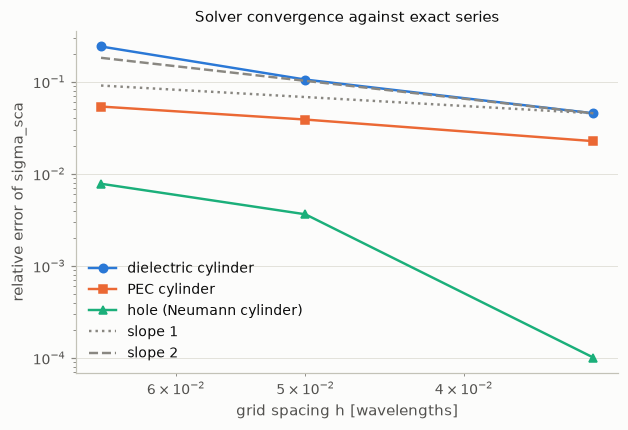

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
hh = np.array(HS)
ax.loglog(hh, np.abs(err_die), "o-", color=CAT[0], label="dielectric cylinder")
ax.loglog(hh, np.abs(err_pec), "s-", color=CAT[1], label="PEC cylinder")
ax.loglog(hh, np.abs(err_neu), "^-", color=CAT[2], label="hole (Neumann cylinder)")
for p, ls in ((1, ":"), (2, "--")):
    ax.loglog(hh, np.abs(err_die[-1]) * (hh / hh[-1]) ** p, ls, color=MUTED, label=f"slope {p}")
ax.invert_xaxis(); ax.set_xlabel("grid spacing h [wavelengths]"); ax.set_ylabel("relative error of sigma_sca")
ax.set_title("Solver convergence against exact series"); ax.legend()
plt.show()

## 2. Cloaks from maps

**(a) The cylindrical cloak.** Let t(x) measure size with respect to the cloak's shape, with t = r for a circle. The cloak with inner boundary t = a and outer boundary t = b is defined by the inverse map from physical to virtual space

$$t'=\frac{b\,(t-a)}{b-a}\ (a<t<b),\qquad x'=x\,\frac{t'}{t},$$

and the identity for t > b. With t = r this is the cylinder cloak of book section 32, eq. (32.11) and (32.18), here for E_z waves; it maps the virtual point (t' = 0) onto the whole inner boundary. At the lining the eigenvalues of A go to zero (radial) and infinity (azimuthal) and eps_zz goes to zero, which a grid cannot represent: the discrete cloak approximates a truncated one, with large but finite values at the first Gauss points outside the lining.

What lines the cloak matters. With the lining at r = r_p slightly outside a, the exterior field of the idealized truncated cloak is that of a bare object of virtual radius delta' = b (r_p - a) / (b - a). A PEC lining gives a PEC cylinder, s_m = -J_m(k0 delta') / H_m(k0 delta'), whose cross-section decreases only logarithmically in delta' because the ideal field does not vanish at the lining. A magnetic wall, the hole of section 1, gives a Neumann cylinder, s_m = -J_m'(k0 delta') / H_m'(k0 delta'), compatible with the ideal field and much faster (notebook 02, section 4). For E_z waves the magnetic wall is the soft-and-hard-surface lining of Greenleaf, Kurylev, Lassas and Uhlmann (2007); it is specific to this polarization. The solver is tested in the cloak medium away from the lining: truncations with r_p = 1.15 and 1.3 and each lining are solved on the three grids and compared with the series. They sample the medium only down to r - a = r_p - a, where the anisotropy is moderate (printed below); the regime r -> a that sets the reported cloak ratios is not separately validated. For the PEC lining of the circle the series is also inverted, to find the delta' that reproduces the computed sigma of the cloak with r_p = a, in units of h, which lumps truncation and discretization error together.

In [8]:
def cloak_map(t, a, b):
    """Inverse map x -> x' of the cloak with inner/outer boundaries t = a, t = b (identity for t >= b)."""
    def g(x):
        tt = t(x)
        return x * jnp.where(tt < b, b * (tt - a) / (b - a), tt) / tt
    return g


def cloak(grid, t, a=1.0, b=2.0):
    """Cloak medium at the Gauss points (vacuum inside the PEC mask, where the map is not used) and the PEC node mask."""
    A, e, det = pullback(cloak_map(t, a, b), grid.gx)
    tg = t(grid.gx.transpose(2, 0, 1)); inside = tg <= a
    A, e = np.where(inside[..., None, None], np.eye(2), A), np.where(inside, 1.0, e)
    return A, e, t(node_xy(grid)) <= a + 1e-12, det[(tg > a) & (tg < b)].min()


def bare(grid, t, a=1.0):
    A, e = grid.vacuum()
    return A, e, t(node_xy(grid)) <= a + 1e-12


def sigma_pec_core(delta):
    """sigma_sca of a PEC cylinder of radius delta in vacuum (virtual-space scatterer of the truncated cloak)."""
    return 4 / K0 * np.sum(np.abs(jv(mm, K0 * delta) / hankel1(mm, K0 * delta))**2)


def sigma_pmc_core(delta):
    """sigma_sca of a Neumann cylinder of radius delta in vacuum (virtual-space scatterer of a truncated cloak with a magnetic wall)."""
    return 4 / K0 * np.sum(np.abs(jvp(mm, K0 * delta) / h1vp(mm, K0 * delta))**2)


def hole_runs(g, t, Ac, ec, a=1.0):
    """Fields for incidence along +x with the interior t <= a made a hole: the cloak medium (Ac, ec) with a hole, and the bare hole.
    Returns the cloak's u, its pinned-node mask, and sigma_sca of the bare hole."""
    Ah, eh, dh = with_hole(g, t, Ac, ec, a); A0, e0, d0 = with_hole(g, t, *g.vacuum(), a)
    return (solve(g, Ah, eh, nopec(g), [(1, 0)], dead=dh), dh,
            partial_waves(g, solve(g, A0, e0, nopec(g), [(1, 0)], dead=d0)[:, 0])[2])


R = {}                                    # per shape: lists over the grids of sigma_bare (PEC), PEC-lined, hole-lined, bare hole
rat_c, d_eff_h, sol_c = [], [], {}
R["circle"] = dict(sb=[], pec=[], hole=[], bhole=[])
print(f"{'h':>8} {'sigma_bare':>11} {'sigma_cloak':>12} {'ratio':>8} {'delta_eff/h':>12} {'min det M':>10}")
for h in HS:
    g = Grid(h)
    Ab, eb, pb = bare(g, t_circle); Ac, ec, pc, dmin = cloak(g, t_circle)
    Ub, Uc = solve(g, Ab, eb, pb, [(1, 0)]), solve(g, Ac, ec, pc, [(1, 0)])
    sb, sc = partial_waves(g, Ub[:, 0])[2], partial_waves(g, Uc[:, 0])[2]
    Uh, dh, sbh = hole_runs(g, t_circle, Ac, ec)
    for k, v in zip(("sb", "pec", "hole", "bhole"), (sb, sc, partial_waves(g, Uh[:, 0])[2], sbh)): R["circle"][k].append(v)
    d_eff = brentq(lambda ld: sigma_pec_core(np.exp(ld)) - sc, np.log(1e-6), np.log(0.5))
    rat_c.append(sc / sb); d_eff_h.append(np.exp(d_eff))
    print(f"{h:8.4f} {sb:11.4f} {sc:12.4f} {rat_c[-1]:8.3f} {np.exp(d_eff) / h:12.2f} {dmin:10.2e}")
    sol_c = dict(g=g, Ub=Ub, Uc=Uc, Uh=Uh, dead=dh)

# The cloak must reduce the cross-section substantially (a truncated lining leaves a remainder that shrinks only
# logarithmically with delta'), and a finer grid must give a thinner effective lining.
check("cloak cuts sigma at least in half at lambda/30 (excess over 0.5)", max(rat_c[-1] - 0.5, 0.0), 0.0)
check("sigma ratio decreases with refinement", float(np.all(np.diff(rat_c) < 0)), 0.0, target=1.0)
check("effective lining radius delta' decreases with refinement", float(np.all(np.diff(d_eff_h) < 0)), 0.0, target=1.0)

# Truncated cloaks: PEC at r_p > a inside the same cloak medium, against the analytic series for delta' = b (r_p - a) / (b - a).
trunc = {}
print(f"{'r_p':>5} {'delta_prime':>11} {'sigma_exact':>11} " + " ".join(f"{'err h=%.4f' % h:>14}" for h in HS))
for rp in (1.15, 1.3):
    dp = 2.0 * (rp - 1.0); sx = sigma_pec_core(dp); row = []
    for h in HS:
        g = Grid(h); Ac, ec, _, _ = cloak(g, t_circle)
        Ut = solve(g, Ac, ec, t_circle(node_xy(g)) <= rp + 1e-12, [(1, 0)])
        row.append(partial_waves(g, Ut[:, 0])[2] / sx - 1)
    trunc[rp] = row
    print(f"{rp:5.2f} {dp:11.2f} {sx:11.4f} " + " ".join(f"{e:+14.3%}" for e in row))
# Tolerances from independent refinement runs: the error is positive and falls roughly as h^2; require a monotone decrease and
# at most 15% at lambda/30 for the less singular truncation (r_p = 1.3), whose error was about 7% there (the 15% bound leaves margin for platform differences).
for rp, row in trunc.items():
    check(f"truncated cloak r_p = {rp}: error falls with refinement", float(np.all(np.diff(np.abs(row)) < 0)), 0.0, target=1.0)
check("truncated cloak r_p = 1.3: error at lambda/30 (excess over 0.15)", max(abs(trunc[1.3][-1]) - 0.15, 0.0), 0.0)

# The same truncations with a magnetic wall (hole up to r_p) against the Neumann series.
trunc_h, trunc_h_abs = {}, {}
print(f"hole-lined truncations (magnetic wall at r_p)\n{'r_p':>5} {'delta_prime':>11} {'sigma_exact':>11} " + " ".join(f"{'err h=%.4f' % h:>14}" for h in HS))
for rp in (1.15, 1.3):
    dp = 2.0 * (rp - 1.0); sx = sigma_pmc_core(dp); row = []
    for h in HS:
        g = Grid(h); Ac, ec, _, _ = cloak(g, t_circle)
        Ut, _, _ = hole_runs(g, t_circle, Ac, ec, a=rp)
        row.append(partial_waves(g, Ut[:, 0])[2] / sx - 1)
    trunc_h[rp] = row; trunc_h_abs[rp] = abs(row[-1]) * sx
    print(f"{rp:5.2f} {dp:11.2f} {sx:11.4f} " + " ".join(f"{e:+14.3%}" for e in row))
# Measured in prototype runs: errors positive and falling roughly as h^3 (about 8% and 3% at lambda/30); require a monotone decrease and
# at most 15% at lambda/30 for the less singular truncation (r_p = 1.3), as for the PEC lining.
for rp, row in trunc_h.items():
    check(f"hole-lined truncated cloak r_p = {rp}: error falls with refinement", float(np.all(np.diff(np.abs(row)) < 0)), 0.0, target=1.0)
check("hole-lined truncated cloak r_p = 1.3: error at lambda/30 (excess over 0.15)", max(abs(trunc_h[1.3][-1]) - 0.15, 0.0), 0.0)

       h  sigma_bare  sigma_cloak    ratio  delta_eff/h  min det M


  0.0667      4.3335       2.3878    0.551         7.26   1.21e-02


  0.0500      4.4019       1.5508    0.352         5.86   2.50e-03


  0.0333      4.4761       1.0269    0.229         5.33   3.33e-04
PASS  cloak cuts sigma at least in half at lambda/30 (excess over 0.5): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  sigma ratio decreases with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  effective lining radius delta' decreases with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
  r_p delta_prime sigma_exact   err h=0.0667   err h=0.0500   err h=0.0333


 1.15        0.30      1.5823       +80.037%       +44.953%       +21.517%


 1.30        0.60      2.8869       +29.489%       +15.424%        +6.734%
PASS  truncated cloak r_p = 1.15: error falls with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  truncated cloak r_p = 1.3: error falls with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  truncated cloak r_p = 1.3: error at lambda/30 (excess over 0.15): got 0, target 0, |diff| 0.00e+00 <= 0e+00
hole-lined truncations (magnetic wall at r_p)
  r_p delta_prime sigma_exact   err h=0.0667   err h=0.0500   err h=0.0333


 1.15        0.30      0.8008       +81.977%       +29.092%        +8.176%


 1.30        0.60      1.9092       +19.178%        +9.050%        +3.350%
PASS  hole-lined truncated cloak r_p = 1.15: error falls with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  hole-lined truncated cloak r_p = 1.3: error falls with refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  hole-lined truncated cloak r_p = 1.3: error at lambda/30 (excess over 0.15): got 0, target 0, |diff| 0.00e+00 <= 0e+00


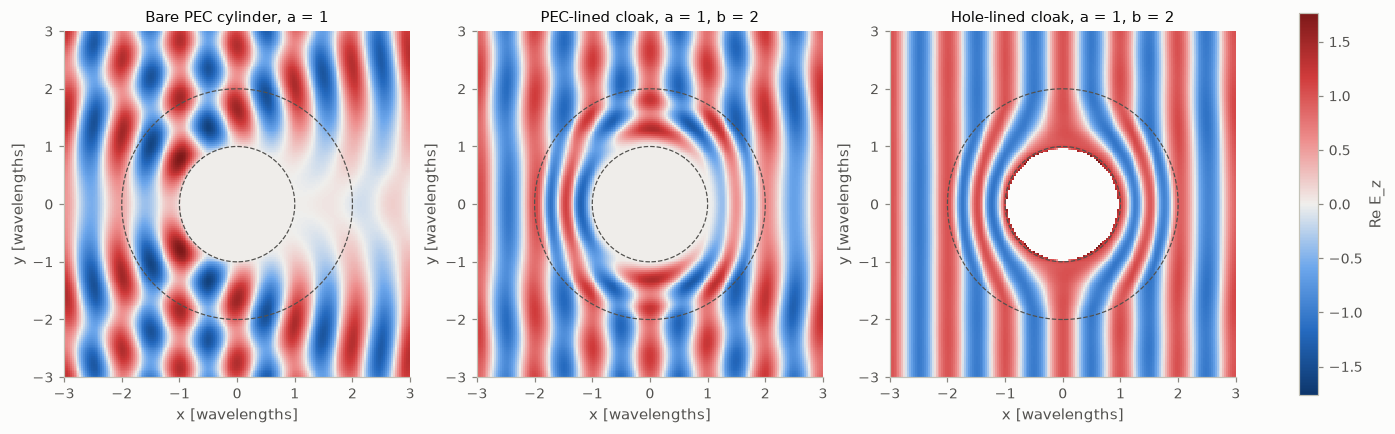

In [9]:
def field_trio(g, Us, dead, titles, t, levels):
    """Re E_z (total field) of three solutions on one shared symmetric scale, with the curves t = levels outlined; the third
    solution is a hole, whose pinned interior nodes (mask dead) are left blank."""
    fig, axs = plt.subplots(1, 3, figsize=(12.6, 4.2))
    E = [np.real(U[:, 0] + np.exp(1j * K0 * g.nodes[:, 0])) for U in Us]
    E[2] = np.where(dead.ravel(), np.nan, E[2])
    v = np.abs(E[0]).max()
    T, ext = g.image(t(node_xy(g)).ravel()); xs = np.linspace(-3, 3, T.shape[0])
    for ax, f, ttl in zip(axs, E, titles):
        im = ax.imshow(g.image(f)[0], extent=ext, cmap=DIV, vmin=-v, vmax=v)
        ax.contour(xs, xs, T, levels=levels, colors=INK2, linewidths=0.8, linestyles="--")
        ax.set_title(ttl); ax.set_xlabel("x [wavelengths]"); ax.set_ylabel("y [wavelengths]"); ax.grid(False)
    fig.colorbar(im, ax=axs, shrink=0.85, label="Re E_z")

g = sol_c["g"]
field_trio(g, [sol_c["Ub"], sol_c["Uc"], sol_c["Uh"]], sol_c["dead"],
           ["Bare PEC cylinder, a = 1", "PEC-lined cloak, a = 1, b = 2", "Hole-lined cloak, a = 1, b = 2"], t_circle, [1.0, 2.0])
plt.show()

The figure shows the total field of the bare PEC cylinder and of both lined cloaks on one color scale (the hole's pinned interior is blank). Both cloaks fill in the shadow; outside r = 2 the PEC-lined cloak still distorts the phase fronts visibly and the hole-lined cloak much less, which (c) quantifies. For the PEC lining the remainder is lining truncation plus discretization error of the singular medium, which the truncated-cloak tables show to be large.

**(b) A cloak of another shape.** The same code, with the size function replaced by t(x) = r / rho(theta) for the squircle rho(theta) = (|cos theta|^4 + |sin theta|^4)^(-1/4), which simplifies to t = (x^4 + y^4)^(1/4). The boundaries are r = a rho(theta) and r = b rho(theta); the inverse map is the one given above with this t. Nothing else changes. The object hidden is a PEC squircle of size a = 1 and the reference is that PEC squircle alone; the hole-lined cloak has the hole inside t <= a.

PASS  t = r / rho(theta) for the squircle: got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-13
       h  sigma_bare  sigma_cloak    ratio  min det M


  0.0667      4.6474       2.1007    0.452   1.82e-02


  0.0500      4.7245       1.5677    0.332   3.39e-03


  0.0333      4.8141       0.9778    0.203   1.86e-03
PASS  squircle cloak cuts sigma at least in half at lambda/30 (excess over 0.5): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  det M > 0 in the squircle cloak (excess of 0 over the minimum): got 0, target 0, |diff| 0.00e+00 <= 0e+00


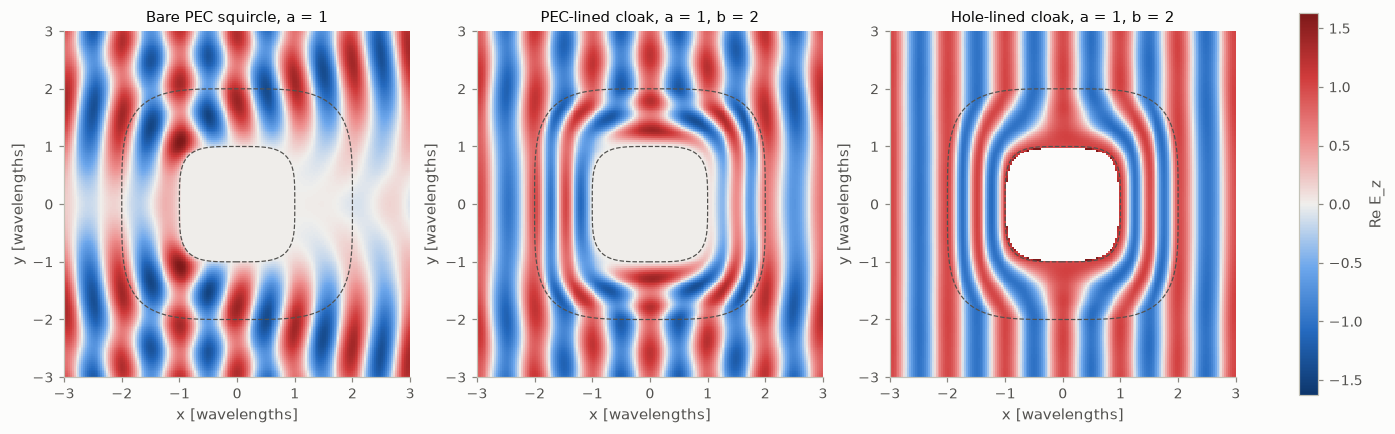

In [10]:
t_squircle = lambda x: (x[0]**4 + x[1]**4) ** 0.25
th_test = np.random.default_rng(3).uniform(0, 2 * np.pi, 1000); r_test = np.random.default_rng(4).uniform(0.2, 3, 1000)
rho = (np.abs(np.cos(th_test))**4 + np.abs(np.sin(th_test))**4) ** -0.25
check("t = r / rho(theta) for the squircle", np.abs(t_squircle([r_test * np.cos(th_test), r_test * np.sin(th_test)]) - r_test / rho).max(), 1e-13)  # float64 rounding

rat_s = []; R["squircle"] = dict(sb=[], pec=[], hole=[], bhole=[])
print(f"{'h':>8} {'sigma_bare':>11} {'sigma_cloak':>12} {'ratio':>8} {'min det M':>10}")
for h in HS:
    g = Grid(h)
    Ab, eb, pb = bare(g, t_squircle); Ac, ec, pc, dmin = cloak(g, t_squircle)
    Ub, Uc = solve(g, Ab, eb, pb, [(1, 0)]), solve(g, Ac, ec, pc, [(1, 0)])
    sb, sc = partial_waves(g, Ub[:, 0])[2], partial_waves(g, Uc[:, 0])[2]
    Uh, dh, sbh = hole_runs(g, t_squircle, Ac, ec)
    for k, v in zip(("sb", "pec", "hole", "bhole"), (sb, sc, partial_waves(g, Uh[:, 0])[2], sbh)): R["squircle"][k].append(v)
    rat_s.append(sc / sb)
    print(f"{h:8.4f} {sb:11.4f} {sc:12.4f} {rat_s[-1]:8.3f} {dmin:10.2e}")
check("squircle cloak cuts sigma at least in half at lambda/30 (excess over 0.5)", max(rat_s[-1] - 0.5, 0.0), 0.0)
check("det M > 0 in the squircle cloak (excess of 0 over the minimum)", max(0.0, -dmin), 0.0)
field_trio(g, [Ub, Uc, Uh], dh, ["Bare PEC squircle, a = 1", "PEC-lined cloak, a = 1, b = 2", "Hole-lined cloak, a = 1, b = 2"], t_squircle, [1.0, 2.0])
plt.show()

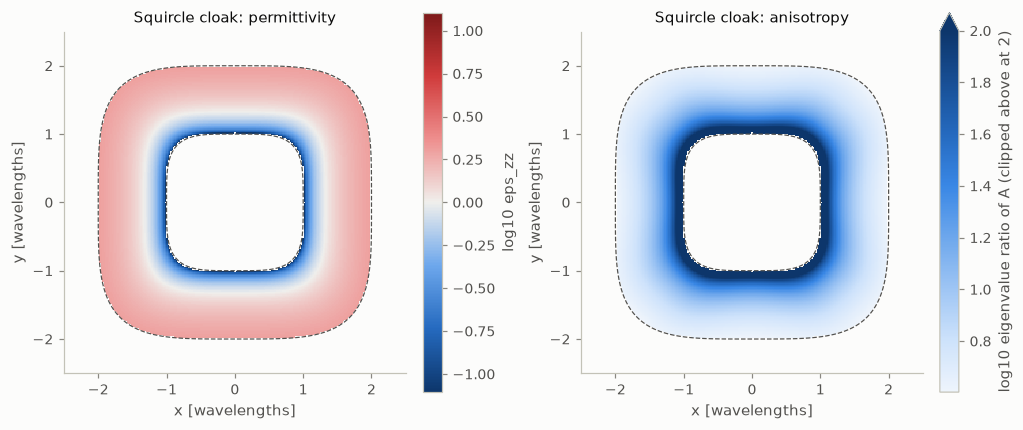

In [11]:
xs = np.linspace(-2.5, 2.5, 251); P = np.stack(np.meshgrid(xs, xs, indexing="ij"), -1)
A_s, e_s, _ = pullback(cloak_map(t_squircle, 1.0, 2.0), P)
tP = t_squircle([P[..., 0], P[..., 1]]); ring = (tP > 1.02) & (tP < 2.0)
ev = np.linalg.eigvalsh(A_s)
le = np.log10(np.where(ring, e_s, 1.0)); lv = np.log10(np.where(ring, ev[..., 1] / ev[..., 0], 1.0))   # evaluate only on the ring
ve = np.abs(le[ring]).max()                                                                       # symmetric about eps_zz = 1
fig, axs = plt.subplots(1, 2, figsize=(9.2, 4.2))
for ax, f, lab, vm, cm, lim in ((axs[0], le, "log10 eps_zz", None, DIV, (-ve, ve)),
                                (axs[1], lv, "log10 eigenvalue ratio of A (clipped above at 2)", 2.0, SEQ, (None, 2.0))):
    im = ax.imshow(np.where(ring, f, np.nan).T, extent=[-2.5, 2.5, -2.5, 2.5], cmap=cm, vmin=lim[0], vmax=lim[1])
    ax.contour(xs, xs, tP.T, levels=[1.0, 2.0], colors=INK2, linewidths=0.8, linestyles="--")
    ax.set_xlabel("x [wavelengths]"); ax.set_ylabel("y [wavelengths]"); ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.85, label=lab, extend="max" if vm else "neither")
axs[0].set_title("Squircle cloak: permittivity"); axs[1].set_title("Squircle cloak: anisotropy")
plt.show()

**(c) The two linings side by side.** The table gives sigma_cloak / sigma_bare for both shapes and linings on the same grids; the reference is the bare PEC object in every row, and the bare hole's sigma is listed for orientation. Expectation tested (notebook 02, section 4): the hole-lined cloak scatters far less at every grid and its residual falls faster. Also printed: the observed order of each ratio between the two finest grids and, for the circle, the virtual radius delta' that the Neumann series needs for the hole-lined sigma, in units of h.

In [12]:
obs_order = lambda r: np.log(r[-2] / r[-1]) / np.log(HS[-2] / HS[-1])
print(f"{'shape':>9} {'h':>8} {'sigma_bare':>11} {'bare hole':>10} {'PEC ratio':>10} {'hole ratio':>11} {'hole/PEC':>9}")
for name, d in R.items():
    for k, h in enumerate(HS):
        print(f"{name:>9} {h:8.4f} {d['sb'][k]:11.4f} {d['bhole'][k]:10.4f} {d['pec'][k] / d['sb'][k]:10.4f} {d['hole'][k] / d['sb'][k]:11.4f} "
              f"{d['hole'][k] / d['pec'][k]:9.3f}")
ratio = {n: {k: np.array(d[k]) / np.array(d["sb"]) for k in ("pec", "hole")} for n, d in R.items()}
for n in R:
    print(f"{n}: observed order of the ratio, PEC lining {obs_order(ratio[n]['pec']):.2f}, hole lining {obs_order(ratio[n]['hole']):.2f}")
d_eff_hole = [brentq(lambda ld: sigma_pmc_core(np.exp(ld)) - sg, np.log(1e-4), np.log(0.7)) for sg in R["circle"]["hole"]]
d_eff_hole = np.exp(d_eff_hole)
print("circle, hole lining: delta'_eff / h = " + ", ".join(f"{d / h:.2f}" for d, h in zip(d_eff_hole, HS)))
print("anisotropy mu_theta / mu_r = (r / (r - a))^2 at the truncation radii r_p = 1.15, 1.3: " + ", ".join(f"{(rp / (rp - 1.0))**2:.0f}" for rp in (1.15, 1.3))
      + f"; at r - a = 0.2 h (order of the first Gauss point outside a hole-lined cloak) for h = 1/30: {((1 + 0.2 / 30) / (0.2 / 30))**2:.0f}")
print("absolute sigma error of the hole-lined truncated cloaks at lambda/30: " + ", ".join(f"r_p = {rp}: {e:.3f}" for rp, e in trunc_h_abs.items())
      + f"; sigma of the hole-lined cloaks there: circle {R['circle']['hole'][-1]:.3f}, squircle {R['squircle']['hole'][-1]:.3f}")

# Thresholds: the hole-lined ratio is 0.033 (circle) and 0.023 (squircle) at lambda/30 in prototype runs, so 0.05 is a margin of about 50%
# (not a fitted bound); the order comparison only asks that the hole lining converge at least one order faster than the PEC lining
# (the measured difference is about 2.4).
for n in R:
    check(f"{n}: hole-lined ratio below PEC-lined ratio at every grid", float(np.all(ratio[n]["hole"] < ratio[n]["pec"])), 0.0, target=1.0)
    check(f"{n}: hole-lined ratio decreases with refinement", float(np.all(np.diff(ratio[n]["hole"]) < 0)), 0.0, target=1.0)
    check(f"{n}: hole-lined ratio at lambda/30 (excess over 0.05)", max(ratio[n]["hole"][-1] - 0.05, 0.0), 0.0)
    check(f"{n}: hole lining converges at least one order faster (shortfall)", max(1.0 - (obs_order(ratio[n]["hole"]) - obs_order(ratio[n]["pec"])), 0.0), 0.0)
check("circle: effective virtual radius of the hole-lined cloak decreases with refinement", float(np.all(np.diff(d_eff_hole) < 0)), 0.0, target=1.0)

    shape        h  sigma_bare  bare hole  PEC ratio  hole ratio  hole/PEC
   circle   0.0667      4.3335     3.4053     0.5510      0.3527     0.640
   circle   0.0500      4.4019     3.4196     0.3523      0.1412     0.401
   circle   0.0333      4.4761     3.4318     0.2294      0.0335     0.146
 squircle   0.0667      4.6474     3.4737     0.4520      0.2752     0.609
 squircle   0.0500      4.7245     3.5155     0.3318      0.0958     0.289
 squircle   0.0333      4.8141     3.5207     0.2031      0.0226     0.111
circle: observed order of the ratio, PEC lining 1.06, hole lining 3.55
squircle: observed order of the ratio, PEC lining 1.21, hole lining 3.56
circle, hole lining: delta'_eff / h = 7.49, 5.04, 3.29
anisotropy mu_theta / mu_r = (r / (r - a))^2 at the truncation radii r_p = 1.15, 1.3: 59, 19; at r - a = 0.2 h (order of the first Gauss point outside a hole-lined cloak) for h = 1/30: 22801
absolute sigma error of the hole-lined truncated cloaks at lambda/30: r_p = 1.15: 0.0

**Reading the table.** The expectation holds for both shapes: the hole-lined ratio is below the PEC-lined one at every grid and converges at a much higher observed order (printed above), as the residuals of notebook 02, section 4 (1 / ln^2 of the offset for a PEC wall, the fourth power for a magnetic wall) suggest. It does not measure either law: the offset of a staircased lining is uncontrolled, three grids fix no exponent, and delta' in units of h is not constant. The suspects for a bad hole lining are cleared as far as the grids go: the staircase and the pinned nodes by the Neumann-cylinder validation, the solver next to a hole in the cloak medium, only down to the offsets of the truncated cloaks, by their relative error, which falls steeply with h. The medium at the first grid points outside the lining of the actual hole-lined cloak is far more anisotropic than anything the truncations sample (printed above), so that regime is not validated. The truncations' absolute errors are of the order of the hole-lined cloaks' own sigma, so the cloaks' residual is truncation mixed with discretization error. The cloaks hide different objects, a PEC cylinder and a magnetic-wall cavity.

## 3. Gauge freedom

Let g be a diffeomorphism of the plane that is the identity outside a disk D and has positive Jacobian determinant. Take an isotropic nonmagnetic object eps'(x') (A' = I) and define medium 1 as its pull-back by g: at the physical point x, put the medium of the object at x' = g(x), transformed by the formula of section 1. The change of variables x' = g(x) in the weak form of the Helmholtz equation gives exactly

$$\int\nabla'v'\cdot\nabla'u'-k_0^2\varepsilon'u'v'\,dx'=\int\nabla v\cdot A\nabla u-k_0^2\varepsilon_{zz}uv\,dx,$$

so E_1(x) = E_0(g(x)) is a solution of medium 1 whenever E_0 solves the object. Outside D, g is the identity, so E_1 = E_0 there: the scattered fields, and with them every far-field or near-field measurement outside D, are identical. This holds for each incident wave and each frequency separately.

**Setup.** The object is a dielectric disk, eps = 3, radius 0.6, centered at (0.3, 0.2), and a second disk, eps = 2, radius 0.3, at (-0.7, -0.5). The diffeomorphism is, in polar coordinates, a twist theta -> theta + alpha w(r) combined with a radial displacement r -> r (1 + beta w(r)), with the smooth window w(r) = (1 - (r/2)^2)^3 inside D (radius 2) and zero outside; alpha = 0.5 and beta = 0.15. Medium 0 is the object, medium 1 its pull-back by g (A = Lambda Lambda^T / det Lambda, eps_zz = eps'(g(x)) / det Lambda), and medium 2 is the naive deformation: the same deformed isotropic object eps'(g(x)), with A = I and no determinant factor. Data are the scattered field at 60 receivers on a circle of radius 3 for 8 incidence directions. If the gauge argument is right, the first relative data difference should sit at the discretization error and shrink with h, and the second should not.

In [13]:
ALPHA, BETA, RD = 0.5, 0.15, 2.0
def Phi(x):
    """Twist by alpha w(r) and dilation by 1 + beta w(r); the identity for r >= RD. (Used as the map x -> x'.)"""
    r2 = x[0]**2 + x[1]**2
    w = jnp.where(r2 < RD**2, (1 - r2 / RD**2) ** 3, 0.0)
    c, s = jnp.cos(ALPHA * w), jnp.sin(ALPHA * w)
    return (1 + BETA * w) * jnp.stack([c * x[0] - s * x[1], s * x[0] + c * x[1]])

DISKS = [((0.3, 0.2), 0.6, 3.0), ((-0.7, -0.5), 0.3, 2.0)]
def eps_obj(x):
    e = jnp.ones(x.shape[:-1])
    for (cx, cy), rad, ee in DISKS:
        e = jnp.where((x[..., 0] - cx)**2 + (x[..., 1] - cy)**2 < rad**2, ee, e)
    return e

_, _, detM = pullback(Phi, np.random.default_rng(0).uniform(-2.6, 2.6, (200000, 2)))
print(f"det(dPhi) over 200000 random points: min {detM.min():.4f}, max {detM.max():.4f}")
# tolerance: the exact minimum is 0.92 (closed form), so 0.5 is a loose guard that also prints the true value
check("minimum of det dPhi (must stay well above 0)", detM.min(), 0.5, target=1.0)

th = 2 * np.pi * np.arange(60) / 60; receivers = 3.0 * np.stack([np.cos(th), np.sin(th)], 1)
dirs = [(np.cos(p), np.sin(p)) for p in 2 * np.pi * np.arange(8) / 8]
no_pec = lambda g: np.zeros((g.n1, g.n1), bool)
err1, err2, nrm0, field = [], [], [], {}
print(f"{'h':>8} {'|d0|':>9} {'|d1-d0|/|d0|':>14} {'|d2-d0|/|d0|':>14}")
for h in HS:
    g = Grid(h); A0, _ = g.vacuum()
    e0 = np.asarray(eps_obj(jnp.asarray(g.gx)))
    A1, e1, _ = pullback(Phi, g.gx, eps_obj)
    e2 = np.asarray(eps_obj(jax.vmap(Phi)(jnp.asarray(g.gx.reshape(-1, 2))).reshape(g.gx.shape)))
    U = [solve(g, A, e, no_pec(g), dirs) for A, e in ((A0, e0), (A1, e1), (A0, e2))]
    d = [sample(g, u, receivers) for u in U]
    nrm0.append(np.linalg.norm(d[0])); err1.append(np.linalg.norm(d[1] - d[0]) / nrm0[-1]); err2.append(np.linalg.norm(d[2] - d[0]) / nrm0[-1])
    print(f"{h:8.4f} {nrm0[-1]:9.4f} {err1[-1]:14.4f} {err2[-1]:14.4f}")
    field = dict(g=g, U=U)
print(f"observed order of the medium-1 difference (two finest grids): {order(err1):.2f}")

# Medium 1 vs 0 differ only by discretization (interface staircasing at Gauss points, O(h) to O(h^2)): require a decrease
# at every refinement and a few percent at lambda/30. Medium 2 is a different object: require an order-one difference
# (at least 0.3) that does not shrink (ratio of finest to coarsest within 25% of one).
check("medium 1 data difference decreases at each refinement", float(np.all(np.diff(err1) < 0)), 0.0, target=1.0)
check("medium 1 data difference at lambda/30 (excess over 0.05)", max(err1[-1] - 0.05, 0.0), 0.0)
check("medium 2 data difference is of order one (shortfall below 0.3)", max(0.3 - err2[-1], 0.0), 0.0)
check("medium 2 data difference does not shrink with h", err2[-1] / err2[0], 0.25, target=1.0)

det(dPhi) over 200000 random points: min 0.9232, max 1.3225
PASS  minimum of det dPhi (must stay well above 0): got 0.923197, target 1, |diff| 7.68e-02 <= 5e-01
       h      |d0|   |d1-d0|/|d0|   |d2-d0|/|d0|


  0.0667    9.1115         0.0935         0.7774


  0.0500    8.9228         0.0507         0.7742


  0.0333    8.7620         0.0277         0.7744
observed order of the medium-1 difference (two finest grids): 1.49
PASS  medium 1 data difference decreases at each refinement: got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  medium 1 data difference at lambda/30 (excess over 0.05): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  medium 2 data difference is of order one (shortfall below 0.3): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  medium 2 data difference does not shrink with h: got 0.99607, target 1, |diff| 3.93e-03 <= 2e-01


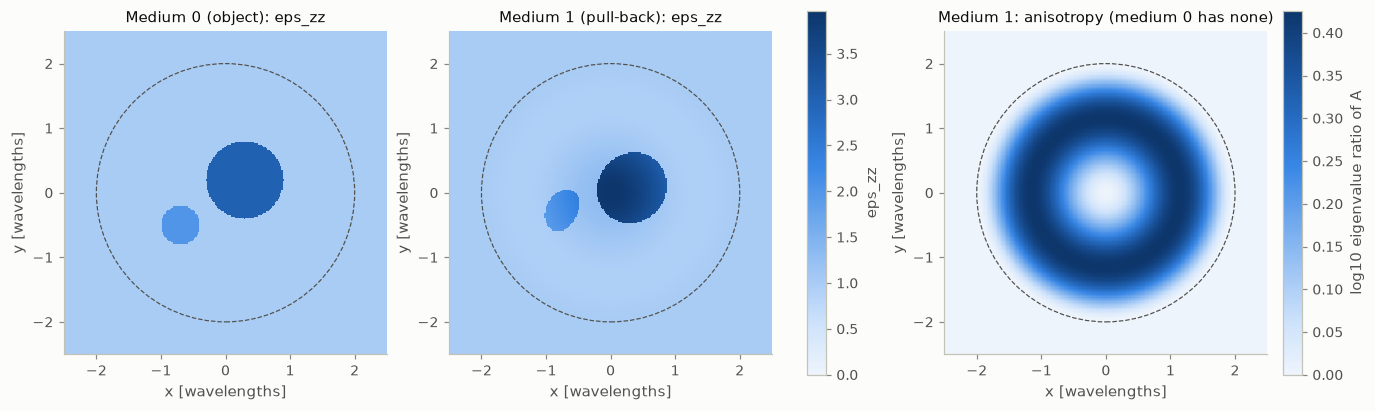

In [14]:
xs = np.linspace(-2.5, 2.5, 251); P = np.stack(np.meshgrid(xs, xs, indexing="ij"), -1)
A1p, e1p, _ = pullback(Phi, P, eps_obj); e0p = np.asarray(eps_obj(jnp.asarray(P)))
ev = np.linalg.eigvalsh(A1p); aniso = np.log10(ev[..., 1] / ev[..., 0])
fig, axs = plt.subplots(1, 3, figsize=(12.4, 4.0))
vmax = max(e0p.max(), e1p.max())
for ax, f, ttl in ((axs[0], e0p, "Medium 0 (object): eps_zz"), (axs[1], e1p, "Medium 1 (pull-back): eps_zz")):
    im = ax.imshow(f.T, extent=[-2.5, 2.5, -2.5, 2.5], cmap=SEQ, vmin=0, vmax=vmax); ax.set_title(ttl)
fig.colorbar(im, ax=axs[:2], shrink=0.85, label="eps_zz")
im2 = axs[2].imshow(aniso.T, extent=[-2.5, 2.5, -2.5, 2.5], cmap=SEQ, vmin=0); axs[2].set_title("Medium 1: anisotropy (medium 0 has none)")
fig.colorbar(im2, ax=axs[2], shrink=0.85, label="log10 eigenvalue ratio of A")
for ax in axs:
    ax.add_patch(plt.Circle((0, 0), RD, fill=False, ec=INK2, lw=0.8, ls="--")); ax.grid(False)
    ax.set_xlabel("x [wavelengths]"); ax.set_ylabel("y [wavelengths]")
plt.show()

medium 1: max |E - E_0| inside D 2.8674; outside D (2.2 < r < 3.5) 0.0267
medium 2: max |E - E_0| inside D 2.0440; outside D (2.2 < r < 3.5) 0.8657
PASS  medium 1: field difference outside D relative to inside (excess over 0.05): got 0, target 0, |diff| 0.00e+00 <= 0e+00


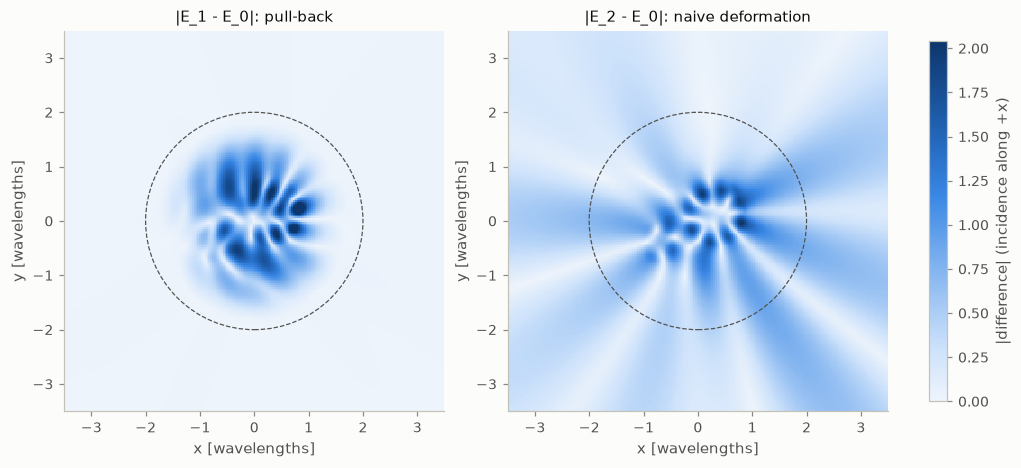

In [15]:
g, (U0, U1, U2) = field["g"], field["U"]
rr = np.hypot(g.X, g.Y).ravel()
dif1, dif2 = np.abs(U1[:, 0] - U0[:, 0]), np.abs(U2[:, 0] - U0[:, 0])
for name, d in (("medium 1", dif1), ("medium 2", dif2)):
    print(f"{name}: max |E - E_0| inside D {d[rr < RD].max():.4f}; outside D (2.2 < r < 3.5) {d[(rr > 2.2) & (rr < 3.5)].max():.4f}")
leak = dif1[(rr > 2.2) & (rr < 3.5)].max() / dif1[rr < RD].max()
check("medium 1: field difference outside D relative to inside (excess over 0.05)", max(leak - 0.05, 0.0), 0.0)  # discretization radiation
fig, axs = plt.subplots(1, 2, figsize=(9.2, 4.2)); v = dif2.max()
for ax, f, ttl in zip(axs, (dif1, dif2), ("|E_1 - E_0|: pull-back", "|E_2 - E_0|: naive deformation")):
    im = ax.imshow(g.image(f, 3.5)[0], extent=[-3.5, 3.5, -3.5, 3.5], cmap=SEQ, vmin=0, vmax=v); ax.set_title(ttl)
    ax.add_patch(plt.Circle((0, 0), RD, fill=False, ec=INK2, lw=0.8, ls="--")); ax.grid(False)
    ax.set_xlabel("x [wavelengths]"); ax.set_ylabel("y [wavelengths]")
fig.colorbar(im, ax=axs, shrink=0.85, label="|difference| (incidence along +x)")
plt.show()

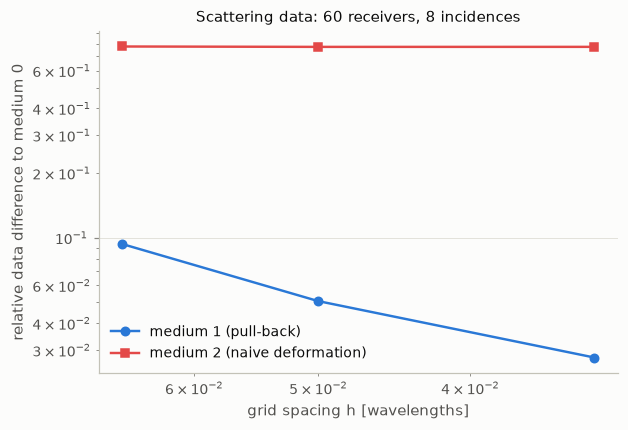

In [16]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.loglog(HS, err1, "o-", color=CAT[0], label="medium 1 (pull-back)")
ax.loglog(HS, err2, "s-", color=CAT[7], label="medium 2 (naive deformation)")
ax.invert_xaxis(); ax.set_xlabel("grid spacing h [wavelengths]"); ax.set_ylabel("relative data difference to medium 0")
ax.set_title("Scattering data: 60 receivers, 8 incidences"); ax.legend()
plt.show()

**Reading the results.** The pull-back medium reproduces the data of the object to discretization accuracy, with a difference that falls under refinement; the naive deformation changes the data at order one and does not converge toward them. For the pull-back, the field difference is confined to D up to what the two discretizations radiate (the inside and outside maxima printed above).

The careful statement: for the E_z equation at one frequency, scattering data outside D cannot distinguish an anisotropic magnetic medium from its image under any diffeomorphism that is the identity outside D (with positive Jacobian, so that A stays positive definite), so such data determine a medium at most up to this group. The statement is about the exact problem; the notebook verifies it for one map, one object and one frequency. The cloak is the borderline case in which the map is no longer a diffeomorphism: it blows a point up to a finite region, the medium is singular on the lining, and the region behind it is invisible to all data. The book's covariance argument (section 29, p. 181, `CLAIMS.md` H3, which requires the map to be the identity outside the device and to preserve topology) makes the field of medium 1 the pulled-back field; reading it as a statement about inverse-problem data is this notebook's own.

## 4. Why the testbed does not have this freedom

The project's forward model is isotropic and nonmagnetic: A = I and only eps_zz varies. In two dimensions a conformal map w(z) keeps A = I and changes only eps_zz. For the map g = w with M the real Jacobian, M = |w'| times a rotation, so adj(M) adj(M)^T / det M = I, and det M = |w'|^2, which gives

$$A=I,\qquad \varepsilon_{zz}=\varepsilon'\,|dw/dz|^{2}\quad\Longleftrightarrow\quad n=n'\,|dw/dz|,$$

which is optical conformal mapping, book section 5, eq. (5.9). The numerical check below uses a Moebius map (book section 5, eq. (5.18)) and a quadratic polynomial map.

**Rigidity.** Suppose a compactly supported gauge transformation maps the class of isotropic nonmagnetic media to itself. Then A stays equal to I, which forces M to be conformal, so g is analytic (or anti-analytic) on D, and a conformal map equal to the identity on an open set is the identity on a connected domain (identity theorem). So no nontrivial compactly supported g has this property: within the testbed's class this gauge freedom is absent. Contrast with the twist-and-dilation map of section 3, whose pull-back is anisotropic inside D (the printed maximum below).

This is consistent with the uniqueness theorems for the scalar equation with an isotropic coefficient, on which the project's inverse problem relies: for a fixed frequency and complete boundary (Dirichlet-to-Neumann) data the coefficient is determined, in dimension three and higher by Sylvester and Uhlmann (1987) and for smooth potentials in two dimensions by Bukhgeim (2008). Those theorems concern complete boundary data of a bounded domain; the testbed uses finite-aperture far-field data with a few incidences, so they motivate identifiability and do not prove it. The anisotropic case is different, as section 3 shows, and singular maps of the cloak type give the non-uniqueness examples of Greenleaf, Lassas and Uhlmann (2003, three dimensions).

In [17]:
a_, b_, c_, d_ = 1.0, 0.5j, 0.4, 1 + 0.2j                     # ad - bc = 1
moebius = lambda z: (a_ * z + b_) / (c_ * z + d_)
d_moebius = lambda z: (a_ * d_ - b_ * c_) / (c_ * z + d_) ** 2
quad = lambda z: z + 0.2 * z**2
d_quad = lambda z: 1 + 0.4 * z
real_map = lambda w: (lambda x: jnp.stack([w(x[0] + 1j * x[1]).real, w(x[0] + 1j * x[1]).imag]))

pts = np.random.default_rng(1).uniform(-1.5, 1.5, (2000, 2)); z = pts[:, 0] + 1j * pts[:, 1]
print(f"{'map':>10} {'max |Lambda Lambda^T / det - I|':>34} {'max rel |1/det Lambda - |dw/dz|^2|':>38}")
for name, w, dw in (("Moebius", moebius, d_moebius), ("quadratic", quad, d_quad)):
    A, e, det = pullback(real_map(w), pts)
    e_A, e_det = np.abs(A - np.eye(2)).max(), np.max(np.abs(det - np.abs(dw(z))**2) / np.abs(dw(z))**2)
    print(f"{name:>10} {e_A:34.2e} {e_det:38.2e}")
    check(f"{name}: Lambda Lambda^T / det Lambda - I", e_A, 1e-12)          # float64 rounding of a 2 x 2 algebraic identity
    check(f"{name}: 1 / det Lambda = |dw/dz|^2 (relative)", e_det, 1e-12)

A_phi, _, _ = pullback(Phi, np.random.default_rng(2).uniform(-1.9, 1.9, (20000, 2)))
print(f"twist-and-dilation map of section 3: max |Lambda Lambda^T / det - I| over D = {np.abs(A_phi - np.eye(2)).max():.3f}")
check("twist-and-dilation map is not conformal (shortfall below 0.05)", max(0.05 - np.abs(A_phi - np.eye(2)).max(), 0.0), 0.0)

       map    max |Lambda Lambda^T / det - I|     max rel |1/det Lambda - |dw/dz|^2|


   Moebius                           4.44e-16                               1.00e-15
PASS  Moebius: Lambda Lambda^T / det Lambda - I: got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-12
PASS  Moebius: 1 / det Lambda = |dw/dz|^2 (relative): got 1.00451e-15, target 0, |diff| 1.00e-15 <= 1e-12
 quadratic                           2.22e-16                               6.54e-16
PASS  quadratic: Lambda Lambda^T / det Lambda - I: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-12
PASS  quadratic: 1 / det Lambda = |dw/dz|^2 (relative): got 6.5405e-16, target 0, |diff| 6.54e-16 <= 1e-12


twist-and-dilation map of section 3: max |Lambda Lambda^T / det - I| over D = 0.633
PASS  twist-and-dilation map is not conformal (shortfall below 0.05): got 0, target 0, |diff| 0.00e+00 <= 0e+00


## Summary

The Q1 solver with a perfectly matched layer reproduces the exact cross-sections of a dielectric, a PEC and a Neumann (hole) cylinder to within a few percent at lambda/30, with errors that fall under refinement. A cloak made from a map and automatic differentiation cuts the cross-section of a hidden object substantially, for the circle and the squircle alike. The lining matters: with a PEC lining the residual falls slowly under refinement, while a hole lining (A = 0, eps_zz = 0, a magnetic wall) leaves far less and falls much faster, as the offset laws of notebook 02, section 4 predict. The solver is checked against the analytic series on truncated cloaks with both linings, which sample the cloak medium only down to r - a = 0.15 and not the limit r -> a; at these grid spacings the residual of each discrete cloak is a mixture of lining truncation and discretization error that the notebook does not separate. In the gauge-freedom experiment the pulled-back anisotropic medium reproduces the scattering data of the isotropic object to discretization accuracy while the naive deformation does not. Conformal maps keep the isotropic nonmagnetic class and are rigid, so the testbed's class has no compactly supported gauge freedom of this kind.

## Caveats and open ends

- The cloak ratios are not converged: they decrease under refinement, and the limit is controlled by the truncation of the lining, but at these grids discretization error of the singular medium contributes substantially (truncated-cloak tables) and, for the hole lining, is comparable to the residual. Three grids support a trend, not an extrapolated value or an exponent. The truncation tests do not reach the offsets r - a of order h that the discrete cloak actually samples.
- The cloaks hide different objects (a PEC object, a magnetic-wall cavity) and are compared with one PEC reference; the staircased lining has an uncontrolled offset.
- The gauge experiment tests one diffeomorphism, one object and one frequency, with differences limited by the discretization error of the disk interfaces, and no map that is not a diffeomorphism.
- The effective lining radius delta', for either lining, absorbs every discretization effect (dispersion and staircase errors of section 1 included) and cannot separate truncation from discretization error.
- The rigidity argument excludes compactly supported conformal gauge maps within the isotropic class, not other non-uniqueness mechanisms (finite-aperture data, noise, limited angles); the cited theorems are for complete boundary data, not the testbed's data.
- Frequency dependence and three-dimensional polarization effects are outside this notebook; the cloak is a single-frequency device here.

## References

- U. Leonhardt and T. Philbin, *Geometry and Light* (Dover, 2010): section 5, eqs. (5.9) and (5.18); section 27, eq. (27.2); section 29 and p. 181; section 32, eqs. (32.5), (32.11), (32.18); section 33. Reading notes and claim checks: `CLAIMS.md`, H1 to H3.
- J. B. Pendry, D. Schurig and D. R. Smith, Controlling electromagnetic fields, *Science* (2006).
- U. Leonhardt, Optical conformal mapping, *Science* (2006).
- A. Greenleaf, M. Lassas and G. Uhlmann, On nonuniqueness for Calderon's inverse problem, *Mathematical Research Letters* (2003).
- A. Greenleaf, Y. Kurylev, M. Lassas and G. Uhlmann, Improvement of cylindrical cloaking with the SHS lining, *Opt. Express* 15, 12717 (2007).
- J. Sylvester and G. Uhlmann, A global uniqueness theorem for an inverse boundary value problem, *Annals of Mathematics* (1987).
- A. L. Bukhgeim, Recovering a potential from Cauchy data in the two-dimensional case, *Journal of Inverse and Ill-Posed Problems* (2008).